# Linear Regression

On the [What is Machine Learning?](00_what_is_machine_learning.qmd) page you fitted a line and a polynomial to data with sliders, and you saw how gradient descent finds the best parameters. In the [Regression](003_regression.ipynb) notebook you trained a random forest as a black box and measured its error with the MAE.

This notebook connects the two. You will fit a line with scikit-learn's `LinearRegression`, read what it learned, and measure how well it fits. Then you will write the training algorithm yourself, in a few lines of numpy, and check that it finds the same line. After that you will use a linear model on real data, make it more flexible with polynomial features, and control that flexibility with regularization.

Linear models are often the first model to try on a new regression problem. They train in a fraction of a second, and you can read what they learned directly from their parameters.

### Outline

- `LinearRegression` in scikit-learn
- Measuring the fit
- Gradient descent from scratch
- More than one feature
- R²
- Polynomial features
- Regularization
- Exercise

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. `LinearRegression` in scikit-learn

We start with the house prices from the What is Machine Learning? page. Each house has a size $x$, in units of 100 m², and a price $y$, in units of €100,000. So $x = 4.5$, $y = 11.3$ is a house of 450 m² that sold for €1.13 million.

In [2]:
# DUMMY DATA (the houses from the What is Machine Learning? page)
# DO NOT MODIFY
x = np.array([0.8, 1.7, 2.6, 3.4, 4.5, 5.3, 6.2, 7.1, 8.0, 9.2])     # size, in 100 m²
y = np.array([3.5, 3.0, 7.8, 7.1, 11.3, 9.7, 14.0, 17.0, 15.8, 19.0])  # price, in €100,000

Text(0, 0.5, 'Price (€100,000)')

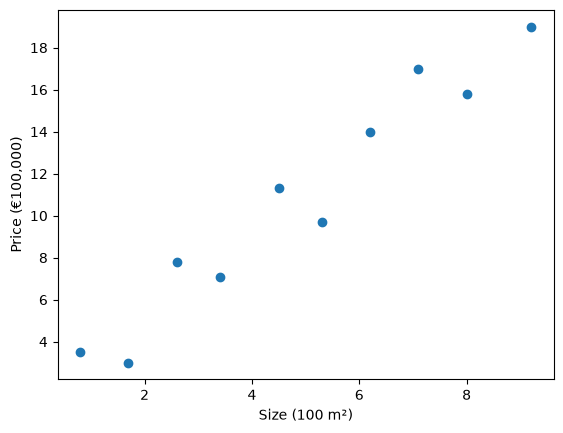

In [3]:
plt.figure(dpi=100)
plt.scatter(x, y)
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')

A straight line has two parameters, the slope and the intercept:

$$
\hat{y} = \text{slope} \cdot x + \text{intercept}
$$

scikit-learn's `LinearRegression` finds the slope and intercept that fit the data best; section 2 makes "best" precise. It expects the features `X` as a table with one column per feature, even when there is only one feature, so we reshape `x` into a single column:

In [4]:
X = x.reshape(-1, 1) # 10 rows, 1 column
X.shape

(10, 1)

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)
model.coef_, model.intercept_

(array([1.945237]), np.float64(1.3272434422457415))

`coef_` holds the slope. In a model with several features it holds one **coefficient** per feature: the number that the feature is multiplied by. `intercept_` holds the intercept.

The parameters have units, and that makes them easy to read:

- The slope is 1.95, in €100,000 per 100 m²: each extra 100 m² adds about €195,000 to the predicted price.
- The intercept is 1.33: the predicted price of a house of size 0, about €133,000 for the plot of land.

The fitted line on the data:

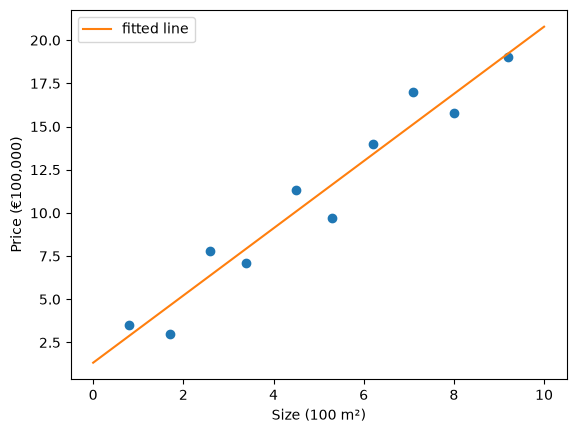

In [6]:
x_line = np.linspace(0, 10, 100) # 100 sizes from 0 to 10, to draw the line

plt.figure(dpi=100)
plt.scatter(x, y)
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), color='tab:orange', label='fitted line')
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')
plt.legend()

To predict the price of a 500 m² house, pass it in the same shape as `X`, one row and one column:

In [7]:
model.predict([[5.0]])

array([11.05342844])

That is about 11 × €100,000 = €1.1 million.

The line does not go through every house. For each house, the **residual** is the true price minus the predicted price, $y - \hat{y}$. It is what the What is Machine Learning? page called the error; residual is the name used in statistics and in the scikit-learn documentation. A residual tells you how far the model is off for one house, and in which direction: a positive residual means the house sold for more than the line predicts, a negative residual for less.

In [8]:
y_pred = model.predict(X)
residuals = y - y_pred
residuals.round(2)

array([ 0.62, -1.63,  1.42, -0.84,  1.22, -1.94,  0.61,  1.86, -1.09,
       -0.22])

The plot draws each residual as a vertical line between the house and the fitted line. Houses above the line have a positive residual, houses below it a negative one.

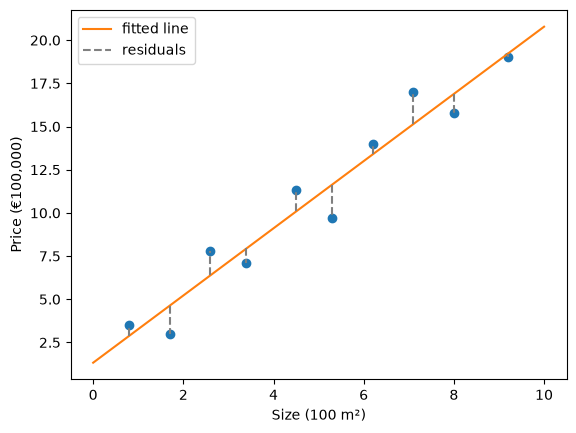

In [9]:
plt.figure(dpi=100)
plt.scatter(x, y)
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), color='tab:orange', label='fitted line')
plt.vlines(x, y_pred, y, color='grey', ls='--', label='residuals')
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')
plt.legend()

The largest residual is about -1.9: the house of 530 m² sold for about €190,000 less than the line predicts. Looking at the residuals of individual points is a good way to find the cases a model gets wrong.

## 2. Measuring the fit

To compare lines, and to say what "best" means, we need one number for the whole dataset. The average of the residuals is not a good measure, because positive and negative residuals cancel out (you saw this in the Regression notebook). Squaring them first gives the mean squared error (MSE), the cost from the What is Machine Learning? page:

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2
$$

`LinearRegression` chooses the slope and intercept with the lowest MSE. Any other line has a higher MSE, for example line A (slope 1.5, intercept 1) and line B (slope 2, intercept 1):

MSE of line A:      9.24
MSE of line B:      1.63
MSE of fitted line: 1.61


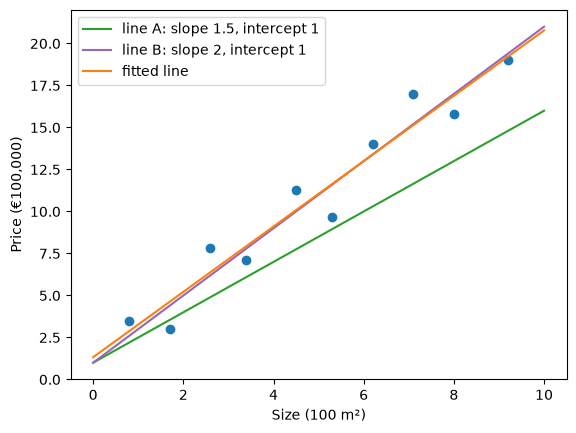

In [10]:
def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

plt.figure(dpi=100)
plt.scatter(x, y)
plt.plot(x_line, 1.5 * x_line + 1, color='tab:green', label='line A: slope 1.5, intercept 1')
plt.plot(x_line, 2 * x_line + 1, color='tab:purple', label='line B: slope 2, intercept 1')
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), color='tab:orange', label='fitted line')
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')
plt.legend()

print(f"MSE of line A:      {mse(y, 1.5 * x + 1):.2f}")
print(f"MSE of line B:      {mse(y, 2 * x + 1):.2f}")
print(f"MSE of fitted line: {mse(y, y_pred):.2f}")

Line B is close to the fitted line, and its MSE is only a little higher. In the [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) notebook you also met the MAE and the RMSE. Each is one line of numpy, and they give the same values as scikit-learn:

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def mae(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def rmse(y, y_pred):
    return np.sqrt(mse(y, y_pred))

print(f"MAE of the fitted line:  {mae(y, y_pred):.2f}   scikit-learn: {mean_absolute_error(y, y_pred):.2f}")
print(f"RMSE of the fitted line: {rmse(y, y_pred):.2f}   scikit-learn: {np.sqrt(mean_squared_error(y, y_pred)):.2f}")

MAE of the fitted line:  1.14   scikit-learn: 1.14
RMSE of the fitted line: 1.27   scikit-learn: 1.27


The RMSE has the units of the price: the fitted line is typically off by about 1.27 × €100,000 = €127,000. The MSE is in squared units, (€100,000)², which are hard to interpret. That is why the MSE is mostly used as the cost during training, and the RMSE or MAE to report how good a model is.

Squaring makes large residuals count much more than small ones. To see this, we add one more house: 300 m², sold for €1.6 million, far more than its size suggests. First we keep the fitted line as it is and only measure again:

In [12]:
x_out = np.append(x, 3.0)  # one extra house: 300 m²
y_out = np.append(y, 16.0) # sold for €1.6 million

y_pred_out = model.predict(x_out.reshape(-1, 1))
print(f"without the extra house: MAE {mae(y, y_pred):.2f}, RMSE {rmse(y, y_pred):.2f}")
print(f"with the extra house:    MAE {mae(y_out, y_pred_out):.2f}, RMSE {rmse(y_out, y_pred_out):.2f}")
print("squared residuals:", ((y_out - y_pred_out) ** 2).round(2))

without the extra house: MAE 1.14, RMSE 1.27
with the extra house:    MAE 1.84, RMSE 2.93
squared residuals: [3.800e-01 2.670e+00 2.000e+00 7.100e-01 1.490e+00 3.750e+00 3.700e-01
 3.470e+00 1.190e+00 5.000e-02 7.809e+01]


One house out of eleven raises the MAE by about 60%, and more than doubles the RMSE. Its residual is about 8.8, so its squared residual is about 78: far more than the squared residuals of the other ten houses together (16). Now we fit a line to the data with the extra house, and compare it with the line without it:

without: slope 1.95, intercept 1.33
with:    slope 1.74, intercept 3.11


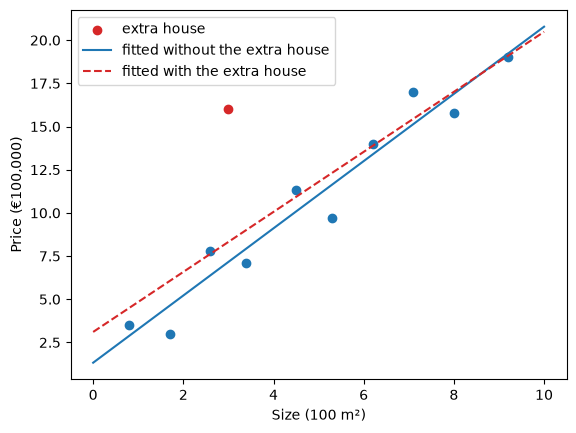

In [13]:
model_out = LinearRegression()
model_out.fit(x_out.reshape(-1, 1), y_out)

plt.figure(dpi=100)
plt.scatter(x, y)
plt.scatter(3.0, 16.0, color='tab:red', label='extra house')
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), label='fitted without the extra house')
plt.plot(x_line, model_out.predict(x_line.reshape(-1, 1)), color='tab:red', ls='--', label='fitted with the extra house')
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')
plt.legend()

print(f"without: slope {model.coef_[0]:.2f}, intercept {model.intercept_:.2f}")
print(f"with:    slope {model_out.coef_[0]:.2f}, intercept {model_out.intercept_:.2f}")

One house moves the whole line. Its squared residual is so large that lowering it reduces the cost more than keeping the line close to the other ten houses, so the fitted line moves towards it and now predicts all small houses too high. This is why you look for such points before training (see the [Data Understanding](006_data_understanding.ipynb) notebook), and why the MAE is less sensitive to them than the RMSE.

## 3. Gradient descent from scratch

`LinearRegression` finds the best line in one call. In this section you find the same line without scikit-learn: you write the model and its training algorithm yourself, and compare the result with `model.coef_` and `model.intercept_`.

First the model, as a Python function:

In [14]:
def predict(x, slope, intercept):
    return slope * x + intercept

The function works on a single number and on a whole array: numpy multiplies every size by the slope and adds the intercept. With the slope and intercept that `LinearRegression` found, it predicts the same price for a 500 m² house as `model.predict` above:

In [15]:
predict(5.0, slope=model.coef_[0], intercept=model.intercept_)

np.float64(11.053428439944778)

On the What is Machine Learning? page you ran gradient descent by pressing a button. Here you write it yourself. It needs the cost, the `mse` function from section 2, and the gradient: how much the cost changes when a parameter changes a little.

You can measure the gradient directly. Change the slope by a tiny amount `h` and see how much the cost changes, then do the same for the intercept. We start at slope 0 and intercept 0.

In [16]:
slope, intercept = 0.0, 0.0
h = 1e-6 # a tiny change

cost_now = mse(y, predict(x, slope, intercept))
gradient_slope = (mse(y, predict(x, slope + h, intercept)) - cost_now) / h
gradient_intercept = (mse(y, predict(x, slope, intercept + h)) - cost_now) / h
print(f"gradient for the slope:     {gradient_slope:.3f}")
print(f"gradient for the intercept: {gradient_intercept:.3f}")

gradient for the slope:     -132.656
gradient for the intercept: -21.640


Both gradients are negative: increasing the slope or the intercept lowers the cost. The slope's gradient is much larger, because the sizes go up to 9.2, so a change in slope moves the line a lot at the right end of the plot.

For the MSE of a line, the gradients also have a formula. You do not need to derive it; the result is:

$$
\frac{\partial\, \text{cost}}{\partial\, \text{slope}} = -\frac{2}{n} \sum_{i=1}^{n} x_i \left( y_i - \hat{y}_i \right)
\qquad
\frac{\partial\, \text{cost}}{\partial\, \text{intercept}} = -\frac{2}{n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)
$$

In numpy:

In [17]:
def gradients(x, y, slope, intercept):
    residuals = y - predict(x, slope, intercept)
    gradient_slope = -2 * np.mean(x * residuals)
    gradient_intercept = -2 * np.mean(residuals)
    return gradient_slope, gradient_intercept

gradients(x, y, slope=0.0, intercept=0.0)

(np.float64(-132.656), np.float64(-21.64))

The formula gives the same numbers as the measurement, apart from the last decimals. It is exact and faster, so we use it from now on.

Gradient descent repeats one step: move each parameter a little against its gradient. The learning rate sets the size of the step. The function below starts at slope 0 and intercept 0, takes `n_steps` steps, and records the parameters and the cost before every step, so we can look at the training afterwards.

In [18]:
def gradient_descent(x, y, learning_rate, n_steps):
    slope, intercept = 0.0, 0.0
    history = []
    for step in range(n_steps):
        history.append((slope, intercept, mse(y, predict(x, slope, intercept))))
        gradient_slope, gradient_intercept = gradients(x, y, slope, intercept)
        slope = slope - learning_rate * gradient_slope
        intercept = intercept - learning_rate * gradient_intercept
    return slope, intercept, np.array(history)

gd_slope, gd_intercept, history = gradient_descent(x, y, learning_rate=0.02, n_steps=2000)
print(f"slope {gd_slope:.4f}, intercept {gd_intercept:.4f}")

slope 1.9452, intercept 1.3272


Compare with the result of `LinearRegression` from section 1:

In [19]:
print(f"gradient descent: slope {gd_slope:.6f}, intercept {gd_intercept:.6f}, cost {mse(y, predict(x, gd_slope, gd_intercept)):.6f}")
print(f"LinearRegression: slope {model.coef_[0]:.6f}, intercept {model.intercept_:.6f}, cost {mse(y, model.predict(X)):.6f}")

gradient descent: slope 1.945237, intercept 1.327243, cost 1.607546
LinearRegression: slope 1.945237, intercept 1.327243, cost 1.607546


They agree to several decimals. `LinearRegression` does not use gradient descent: for a linear model with the MSE as the cost, a formula gives the best parameters in one calculation. Gradient descent reaches the same result in steps, and it also works for models that have no such formula. You will see it again in the [Gradient Boosting](011_gradient_boosting.ipynb) notebook.

The plot shows the line before training and after 5, 20, 100 and 2000 steps.

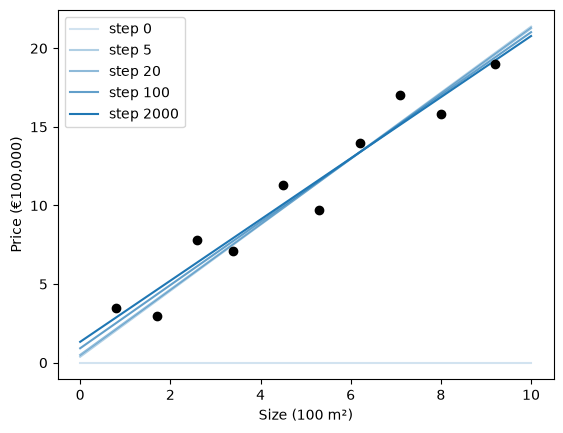

In [20]:
plt.figure(dpi=100)
plt.scatter(x, y, color='black', zorder=3)
for step, alpha in zip([0, 5, 20, 100, 1999], [0.2, 0.35, 0.5, 0.7, 1.0]):
    s, b, _ = history[step]
    plt.plot(x_line, predict(x_line, s, b), color='tab:blue', alpha=alpha, label=f'step {step + 1 if step == 1999 else step}')
plt.xlabel('Size (100 m²)')
plt.ylabel('Price (€100,000)')
plt.legend()

Before training the line is flat at 0. The first steps mostly raise the slope, and the last ones fine-tune the slope and the intercept together. The cost before each step:

Text(0, 0.5, 'Cost (MSE)')

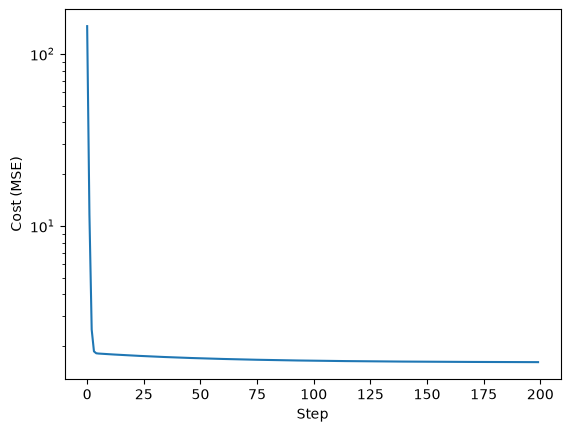

In [21]:
plt.figure(dpi=100)
plt.plot(history[:200, 2]) # the first 200 steps; after that the cost hardly changes
plt.yscale('log') # logarithmic axis: the cost drops from about 140 to below 2
plt.xlabel('Step')
plt.ylabel('Cost (MSE)')

The plot shows the first 200 steps; after that the cost hardly changes. It drops quickly in the first steps and then levels off at about 1.61, the MSE of the line that `LinearRegression` found: the lowest cost a line can get on this data.

Now the learning rate. The next cell runs 100 steps with four learning rates. On the left is the cost before each step, on the right the slope. The run with learning rate 0.034 is left out of the right plot, because its slope jumps far off the scale.

learning rate 0.001: cost after 100 steps 1.811
learning rate 0.02: cost after 100 steps 1.646
learning rate 0.03: cost after 100 steps 1.623
learning rate 0.034: cost after 100 steps 6.562e+13


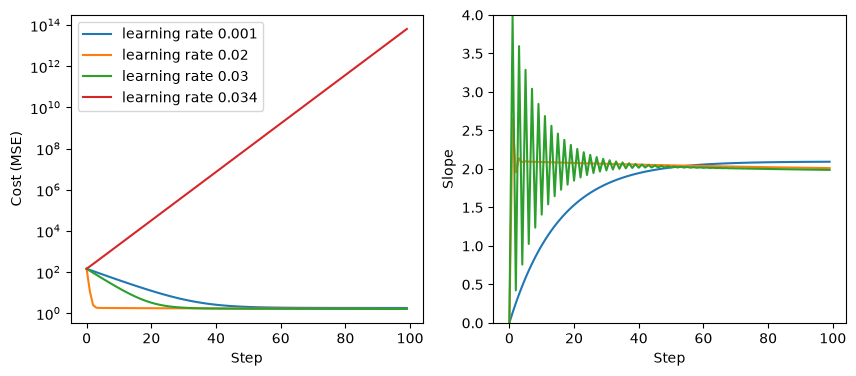

In [22]:
fig, (ax_cost, ax_slope) = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
for learning_rate in [0.001, 0.02, 0.03, 0.034]:
    _, _, h = gradient_descent(x, y, learning_rate, n_steps=100)
    ax_cost.plot(h[:, 2], label=f'learning rate {learning_rate}')
    if learning_rate < 0.034:
        ax_slope.plot(h[:, 0], label=f'learning rate {learning_rate}')
    print(f"learning rate {learning_rate}: cost after 100 steps {h[-1, 2]:.4g}")
ax_cost.set_yscale('log')
ax_cost.set_xlabel('Step')
ax_cost.set_ylabel('Cost (MSE)')
ax_slope.set_ylim(0, 4)
ax_slope.set_xlabel('Step')
ax_slope.set_ylabel('Slope')
ax_cost.legend()

These are the behaviors from the demo on the What is Machine Learning? page:

- 0.001 is too small. The cost goes down slowly, and on the right the slope climbs slowly.
- 0.02 brings the cost down within a few steps.
- 0.03 overshoots. The slope zigzags around its final value: every step jumps past the bottom to the other side, and the jumps get smaller until it settles.
- 0.034 diverges. Each jump lands further from the bottom than the last, and the cost grows without limit.

After 100 steps none of the three is exactly at the minimum of 1.61 yet (see the printed costs), because the intercept changes slowly; the 2000-step run above shows the rest of the way. The difference between a learning rate that works and one that diverges can be small. Try a few values between 0.03 and 0.034 yourself.

## 4. More than one feature

Real problems have more than one feature. A linear model gives each feature its own coefficient:

$$
\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b
$$

where $w_1$ to $w_n$ are the coefficients and $b$ is the intercept. Each coefficient says how much the prediction changes when its feature goes up by one unit and all other features stay the same.

We use the Palmer penguins data: measurements of penguins of three species on islands in Antarctica. We predict the body mass of a penguin, in grams, from three measurements in millimeters: the length of its flipper (wing), and the length and depth of its culmen (the upper ridge of the bill):

<img src="../images/012_linear_regression/penguin_measurements.png" alt="Drawing of a penguin with the three measurements marked: flipper length along the flipper, culmen length along the top of the bill from its base to the tip, and culmen depth from the top to the bottom of the bill at its base" width="90%">

Two penguins have no measurements, so we leave them out.

In [23]:
from sklearn.datasets import fetch_openml

penguins = fetch_openml(name='penguins', version=1, as_frame=True).frame
features = ['flipper_length_mm', 'culmen_length_mm', 'culmen_depth_mm']
penguins = penguins.dropna(subset=features + ['body_mass_g'])
X_penguins, y_penguins = penguins[features], penguins['body_mass_g']
pd.concat([X_penguins, y_penguins], axis=1).head()

,flipper_length_mm,culmen_length_mm,culmen_depth_mm,body_mass_g
0,181.0,39.1,18.7,3750.0
1,186.0,39.5,17.4,3800.0
2,195.0,40.3,18.0,3250.0
4,193.0,36.7,19.3,3450.0
5,190.0,39.3,20.6,3650.0


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_penguins, y_penguins, test_size=0.2, random_state=0)

model_penguins = LinearRegression()
model_penguins.fit(X_train, y_train)
pd.Series(model_penguins.coef_, index=features)

flipper_length_mm    48.215082
culmen_length_mm      7.120022
culmen_depth_mm       7.655125
dtype: float64

The flipper length coefficient is about 48: of two penguins with the same bill, the one with a 1 mm longer flipper has a predicted body mass that is 48 g higher.

The size of a coefficient depends on the units of its feature. If you measure the flipper length in centimeters instead of millimeters, 1 cm is a 10 times larger step than 1 mm:

In [25]:
X_train_cm = X_train.copy()
X_train_cm['flipper_length_mm'] = X_train_cm['flipper_length_mm'] / 10 # now in cm

model_cm = LinearRegression()
model_cm.fit(X_train_cm, y_train)

print("flipper length coefficient, in mm:", model_penguins.coef_[0].round(1))
print("flipper length coefficient, in cm:", model_cm.coef_[0].round(1))
print("same predictions:", np.allclose(model_penguins.predict(X_train), model_cm.predict(X_train_cm)))

flipper length coefficient, in mm: 48.2
flipper length coefficient, in cm: 482.2
same predictions: True


The coefficient is 10 times larger and the predictions are exactly the same. Only the units changed, not the model. So a large coefficient does not mean that a feature is important, and a small one does not mean it is unimportant.

To compare coefficients, first put all features on the same scale. `StandardScaler`, from the [Data Preparation](005_data_prep.ipynb) notebook, gives every feature a mean of 0 and a standard deviation of 1. Fit it on the training data only:

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)
pd.Series(model_scaled.coef_, index=features)

flipper_length_mm    694.243552
culmen_length_mm      39.125912
culmen_depth_mm       14.865174
dtype: float64

Now each coefficient is the change in the predicted body mass when its feature goes up by one standard deviation, a typical difference between two penguins. Flipper length has by far the largest effect. For plain linear regression, scaling only changes how you read the coefficients, not the predictions. Section 7 shows a model where scaling changes the result.

Finally the MAE on the test set, next to the baseline that always predicts the mean of the training targets:

In [27]:
y_pred_penguins = model_penguins.predict(X_test)
y_pred_baseline = np.full(len(y_test), y_train.mean())
print(f"MAE linear model: {mean_absolute_error(y_test, y_pred_penguins):.0f} g")
print(f"MAE baseline:     {mean_absolute_error(y_test, y_pred_baseline):.0f} g")

MAE linear model: 310 g
MAE baseline:     619 g


## 5. R²

An MAE of 310 g is much better than the baseline's 619 g. **R²** (R-squared, also called the coefficient of determination) puts that comparison with the baseline into one number:

$$
R^2 = 1 - \frac{\text{sum of the squared residuals of the model}}{\text{sum of the squared residuals of the mean}}
$$

To see what that means, back to the houses. On the left, the "model" is the mean price; on the right, the line fitted in section 1.

Text(0, 0.5, 'Price (€100,000)')

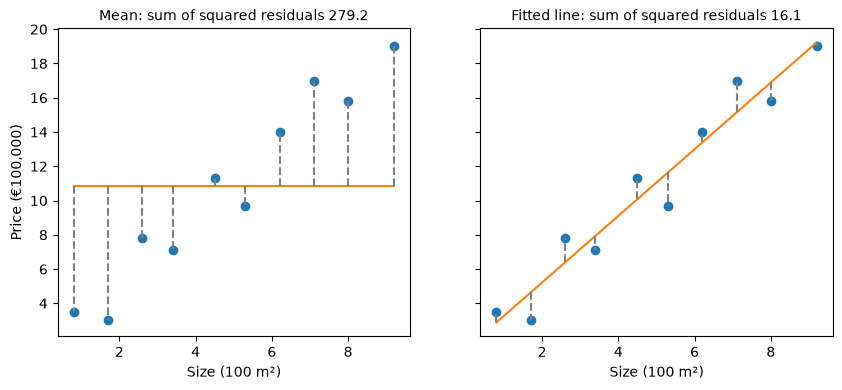

In [28]:
y_mean = np.full_like(y, y.mean())
y_fit = model.predict(X)
sse_mean = np.sum((y - y_mean) ** 2)
sse_fit = np.sum((y - y_fit) ** 2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100, sharey=True)
for ax, y_hat, title in [(axes[0], y_mean, f'Mean: sum of squared residuals {sse_mean:.1f}'),
                         (axes[1], y_fit, f'Fitted line: sum of squared residuals {sse_fit:.1f}')]:
    ax.scatter(x, y)
    ax.plot(x, y_hat, color='tab:orange')
    ax.vlines(x, y_hat, y, color='grey', ls='--')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Size (100 m²)')
axes[0].set_ylabel('Price (€100,000)')

In [29]:
r2 = 1 - sse_fit / sse_mean
r2

np.float64(0.9424223037069027)

The line removes about 94% of the squared error that the mean leaves. scikit-learn computes the same value with `r2_score`, and the `.score()` method of every regression model returns R²:

In [30]:
from sklearn.metrics import r2_score
print(r2_score(y, model.predict(X)))
print(model.score(X, y))

0.9424223037069027
0.9424223037069027


How to read R²:

- R² = 1: perfect predictions, every residual is 0.
- R² = 0: no better than always predicting the mean.
- R² below 0: worse than always predicting the mean. A model can do this, for example on test data.

The mean itself, and a flat line at €1.5 million, as examples:

In [31]:
print("mean:                    ", r2_score(y, y_mean))
print("flat line at €1.5 million:", r2_score(y, predict(x, slope=0, intercept=15)))

mean:                     0.0
flat line at €1.5 million: -0.6258112580409458


R² has no units, so you can compare it between problems. That also makes it easy to read too much into it: whether an R² of 0.6 is good depends on the problem, just like an MAE. Report it next to an error in the units of the target, such as the MAE or the RMSE.

For the penguin model on the test set:

In [32]:
model_penguins.score(X_test, y_test)

0.7210757528501679

An R² of 0.72: the linear model explains about 72% of the variation in body mass between the penguins in the test set.

## 6. Polynomial features

On the What is Machine Learning? page you fitted polynomials to traffic data:

$$
\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_n x^n
$$

This is a linear model too. Treat $x$, $x^2$, $x^3$, ... as separate features, and the polynomial is a sum of coefficient × feature, exactly like the model in section 4. Only the features are new.

scikit-learn's `PolynomialFeatures` creates these columns. For three values of $x$ and degree 3:

In [33]:
from sklearn.preprocessing import PolynomialFeatures

x_demo = np.array([[1], [2], [3]])
poly = PolynomialFeatures(degree=3, include_bias=False)
pd.DataFrame(poly.fit_transform(x_demo), columns=poly.get_feature_names_out(['x']))

,x,x^2,x^3
0,1.0,1.0,1.0
1,2.0,4.0,8.0
2,3.0,9.0,27.0


`include_bias=False` leaves out a column of ones; `LinearRegression` adds its own intercept.

Now the traffic data from the What is Machine Learning? page. $x$ is the time of day in hours from noon ($x = -4$ is 8:00), $y$ is the delay in minutes. The training data and the test data, measured on other days, are the points from the demos in sections 5 and 6 of that page.

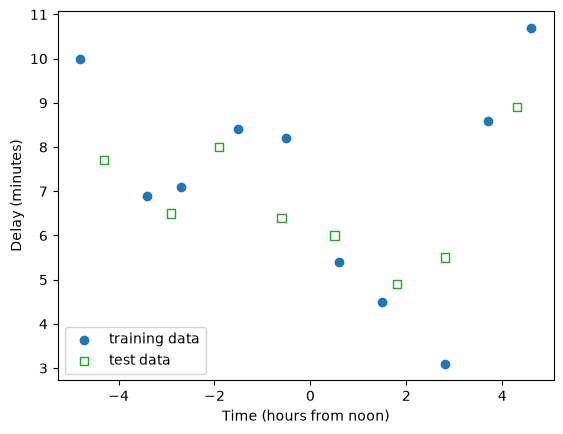

In [34]:
# DUMMY DATA (the traffic data from the What is Machine Learning? page)
# DO NOT MODIFY
x_traffic = np.array([-4.8, -3.4, -2.7, -1.5, -0.5, 0.6, 1.5, 2.8, 3.7, 4.6])      # hours from noon
y_traffic = np.array([10.0, 6.9, 7.1, 8.4, 8.2, 5.4, 4.5, 3.1, 8.6, 10.7])         # delay, in minutes
x_traffic_test = np.array([-4.3, -2.9, -1.9, -0.6, 0.5, 1.8, 2.8, 4.3])
y_traffic_test = np.array([7.7, 6.5, 8.0, 6.4, 6.0, 4.9, 5.5, 8.9])

plt.figure(dpi=100)
plt.scatter(x_traffic, y_traffic, label='training data')
plt.scatter(x_traffic_test, y_traffic_test, marker='s', facecolors='none', edgecolors='tab:green', label='test data')
plt.xlabel('Time (hours from noon)')
plt.ylabel('Delay (minutes)')
plt.legend()

High powers produce very large numbers. At $x = 4.8$, $x^9$ is about 1.4 million, while $x$ itself is below 5. With columns of such different sizes the calculation of the best parameters becomes inaccurate, so we scale the polynomial columns with a `StandardScaler` before fitting.

That makes three steps: create the polynomial columns, scale them, fit the model. To predict, the new data goes through the same steps, with the polynomial features and the scaler that were fitted on the training data. Two small functions keep this short:

In [35]:
def fit_polynomial(x_train, y_train, degree, model):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    scaler = StandardScaler()
    features = scaler.fit_transform(poly.fit_transform(x_train.reshape(-1, 1)))
    model.fit(features, y_train)
    return poly, scaler, model

def predict_polynomial(poly, scaler, model, x_new):
    features = scaler.transform(poly.transform(x_new.reshape(-1, 1)))
    return model.predict(features)

Chaining steps by hand like this is what a `Pipeline` does for you. You will meet it in the [Pipelines & ColumnTransformer](008_advanced_scikitlearn.ipynb) notebook.

Degrees 1, 4 and 9, with the training and test cost of each:

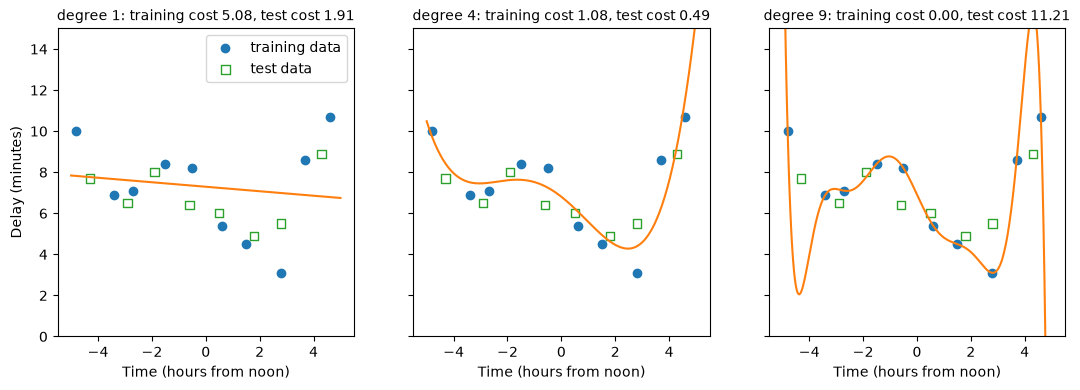

In [36]:
x_curve = np.linspace(-5, 5, 300) # to draw the curves

fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=100, sharey=True)
for ax, degree in zip(axes, [1, 4, 9]):
    fitted = fit_polynomial(x_traffic, y_traffic, degree, LinearRegression())
    train_cost = mse(y_traffic, predict_polynomial(*fitted, x_traffic))
    test_cost = mse(y_traffic_test, predict_polynomial(*fitted, x_traffic_test))
    ax.scatter(x_traffic, y_traffic, label='training data')
    ax.scatter(x_traffic_test, y_traffic_test, marker='s', facecolors='none', edgecolors='tab:green', label='test data')
    ax.plot(x_curve, predict_polynomial(*fitted, x_curve), color='tab:orange')
    ax.set_title(f'degree {degree}: training cost {train_cost:.2f}, test cost {test_cost:.2f}', fontsize=10)
    ax.set_xlabel('Time (hours from noon)')
axes[0].set_ylabel('Delay (minutes)')
axes[0].set_ylim(0, 15)
axes[0].legend()

`fitted` holds the three objects that `fit_polynomial` returns, and `*fitted` passes them on to `predict_polynomial` in the same order.

The costs for all degrees from 1 to 9:

In [37]:
rows = []
for degree in range(1, 10):
    fitted = fit_polynomial(x_traffic, y_traffic, degree, LinearRegression())
    rows.append({'degree': degree,
                 'training cost': mse(y_traffic, predict_polynomial(*fitted, x_traffic)),
                 'test cost': mse(y_traffic_test, predict_polynomial(*fitted, x_traffic_test))})
pd.DataFrame(rows).round(2)

,degree,training cost,test cost
0,1,5.08,1.91
1,2,3.15,1.22
2,3,2.15,0.89
3,4,1.08,0.49
4,5,0.46,0.89
5,6,0.23,1.80
6,7,0.16,2.11
7,8,0.06,4.49
8,9,0.00,11.21


These are the numbers from the demos on the What is Machine Learning? page: the training cost goes down with every degree, to 0 at degree 9, and the test cost is lowest at degree 4.

On that page you chose the degree by looking at the test cost. As section 6 of the page explains, a choice like this should be made on validation data, so that the test set stays unseen until the end. In the Modeling & Evaluation notebook you did this with cross-validation. With only 10 training points, each fold of a 5-fold cross-validation would validate on 2 points, which is too few. So here are more observations from the same road: 30 days, from the same curve and with the same amount of noise.

Text(0, 0.5, 'Delay (minutes)')

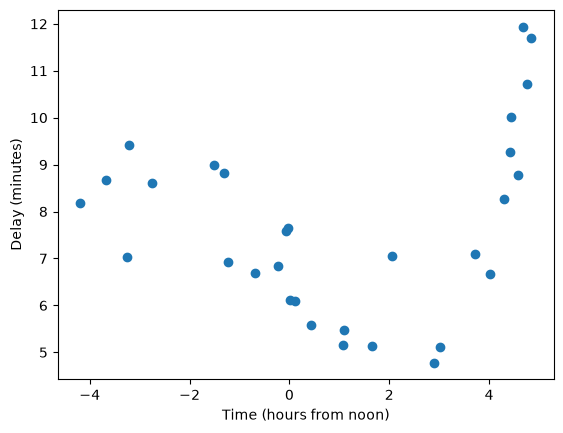

In [38]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
def traffic_curve(x): # the degree-4 curve behind the traffic data
    t = x / 5
    return 6.8 - 5.08 * t - 1.71 * t**2 + 6.98 * t**3 + 5.6 * t**4

rng = np.random.default_rng(4) # fixed seed so that everyone gets the same data
x_more = np.sort(rng.uniform(-5, 5, 30))
y_more = traffic_curve(x_more) + rng.normal(0, 0.96, 30)

plt.figure(dpi=100)
plt.scatter(x_more, y_more)
plt.xlabel('Time (hours from noon)')
plt.ylabel('Delay (minutes)')

The scaler has to be fitted on the training part of each fold only, so we cannot transform all data first and then call `cross_val_score`. Instead we write the cross-validation loop ourselves with `KFold`, which gives the row numbers of the training and validation part of each fold:

validation cost per degree: [3.76, 2.02, 1.01, 0.89, 1.01, 1.16, 3.01, 4.17, 21.52, 54.37, 135.49, 1922.15]


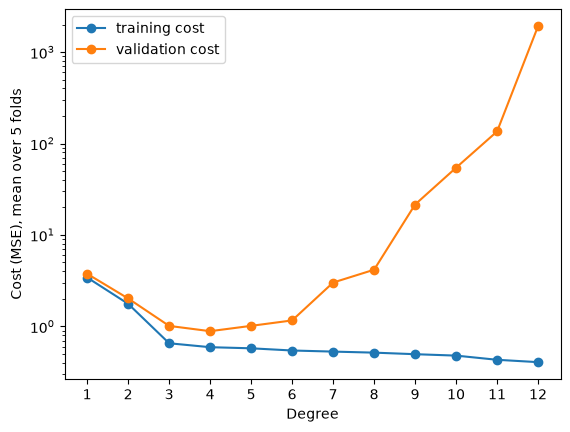

In [39]:
from sklearn.model_selection import KFold

def cross_validate_polynomial(x, y, degree, model):
    train_costs, val_costs = [], []
    for train_idx, val_idx in KFold(n_splits=5, shuffle=True, random_state=0).split(x):
        fitted = fit_polynomial(x[train_idx], y[train_idx], degree, model)
        train_costs.append(mse(y[train_idx], predict_polynomial(*fitted, x[train_idx])))
        val_costs.append(mse(y[val_idx], predict_polynomial(*fitted, x[val_idx])))
    return np.mean(train_costs), np.mean(val_costs)

degrees = range(1, 13)
costs = np.array([cross_validate_polynomial(x_more, y_more, degree, LinearRegression()) for degree in degrees])

plt.figure(dpi=100)
plt.plot(degrees, costs[:, 0], marker='o', label='training cost')
plt.plot(degrees, costs[:, 1], marker='o', label='validation cost')
plt.yscale('log')
plt.xticks(degrees)
plt.xlabel('Degree')
plt.ylabel('Cost (MSE), mean over 5 folds')
plt.legend()

print("validation cost per degree:", costs[:, 1].round(2).tolist())

The same pattern as on the What is Machine Learning? page. The training cost goes down with every degree. The validation cost is lowest at degree 4, rises slowly after that, and very steeply from degree 7 on (the y-axis is logarithmic). Cross-validation finds the degree the data was made with, without using the test data.

## 7. Regularization

Choosing the degree is one way to control how flexible a model is. **Regularization** is another: keep the flexible model, but make large coefficients expensive. **Ridge regression** adds a penalty to the cost:

$$
\text{cost} = \text{MSE} + \alpha \sum_{j=1}^{n} w_j^2
$$

The penalty is the sum of the squared coefficients (the intercept is not included), multiplied by $\alpha$ (alpha). With $\alpha = 0$ this is plain linear regression. The larger $\alpha$, the more a large coefficient adds to the cost, so training keeps the coefficients smaller. Like the degree, $\alpha$ is a hyperparameter: you choose it before training.

The penalty adds up the squared coefficients of all features, and section 4 showed that the size of a coefficient depends on the units of its feature. Without scaling, the penalty would hit some features much harder than others. So for Ridge regression, scaling changes the result, and you should always scale the features first. `fit_polynomial` already does.

Degree 9 on the 10 traffic points overfits badly: its test cost is 11.21. Here is the same degree with Ridge regression and three values of $\alpha$, next to $\alpha = 0$:

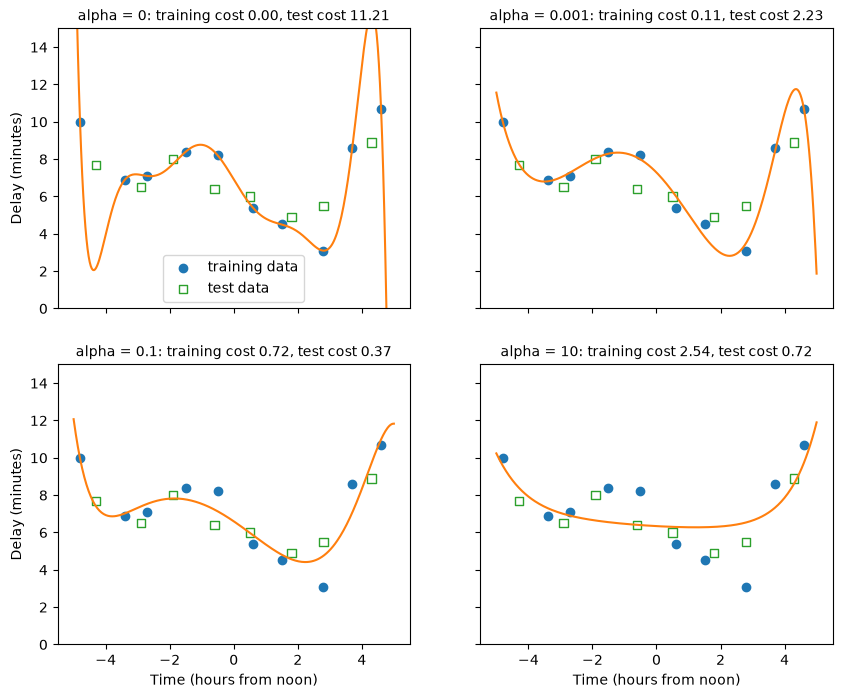

In [40]:
from sklearn.linear_model import Ridge

fig, axes = plt.subplots(2, 2, figsize=(10, 8), dpi=100, sharex=True, sharey=True)
ridge_models = {}
for ax, alpha in zip(axes.flat, [0, 0.001, 0.1, 10]):
    model_alpha = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    fitted = fit_polynomial(x_traffic, y_traffic, 9, model_alpha)
    ridge_models[alpha] = fitted[2]
    train_cost = mse(y_traffic, predict_polynomial(*fitted, x_traffic))
    test_cost = mse(y_traffic_test, predict_polynomial(*fitted, x_traffic_test))
    ax.scatter(x_traffic, y_traffic, label='training data')
    ax.scatter(x_traffic_test, y_traffic_test, marker='s', facecolors='none', edgecolors='tab:green', label='test data')
    ax.plot(x_curve, predict_polynomial(*fitted, x_curve), color='tab:orange')
    ax.set_title(f'alpha = {alpha}: training cost {train_cost:.2f}, test cost {test_cost:.2f}', fontsize=10)
for ax in axes[1]:
    ax.set_xlabel('Time (hours from noon)')
for ax in axes[:, 0]:
    ax.set_ylabel('Delay (minutes)')
axes[0, 0].set_ylim(0, 15)
axes[0, 0].legend()

- With $\alpha = 0.001$ the curve loses most of its swings, and the test cost drops from 11.21 to about 2.2.
- With $\alpha = 0.1$ the test cost is 0.37, lower than degree 4 without regularization (0.49).
- With $\alpha = 10$ the curve is too stiff. The training cost goes up to 2.54 and the test cost goes up again: the model underfits.

Regularization works by keeping the coefficients small. The plot shows the size of the 9 coefficients, for $x$ up to $x^9$, for each $\alpha$:

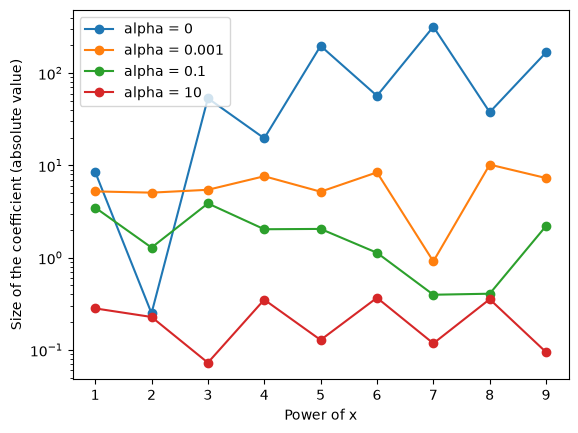

In [41]:
plt.figure(dpi=100)
for alpha, fitted_model in ridge_models.items():
    plt.plot(range(1, 10), np.abs(fitted_model.coef_), marker='o', label=f'alpha = {alpha}')
plt.yscale('log')
plt.xlabel('Power of x')
plt.ylabel('Size of the coefficient (absolute value)')
plt.legend()

Without regularization, several coefficients are in the hundreds. The degree-9 curve is a sum of very large terms that almost cancel each other out at the training points, and swing wildly between them. The larger $\alpha$, the smaller all coefficients get.

$\alpha$ is a hyperparameter, so choose it with cross-validation, not on the test set. We take the 30 observations and a degree that is far too high, 12, and try a range of $\alpha$ values:

validation cost per alpha: [38.14, 14.58, 4.99, 1.55, 0.93, 0.96, 1.19, 1.76]


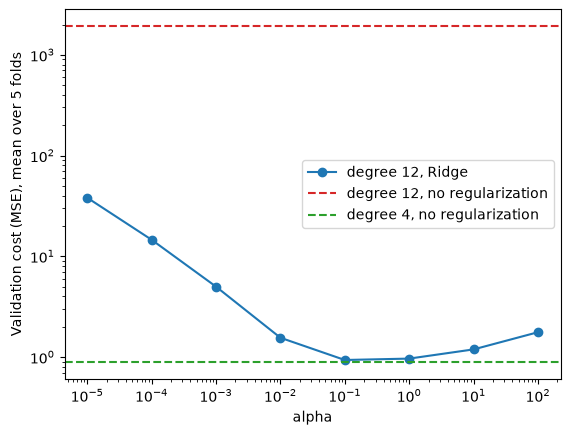

In [42]:
alphas = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
ridge_val_costs = [cross_validate_polynomial(x_more, y_more, 12, Ridge(alpha=alpha))[1] for alpha in alphas]

plt.figure(dpi=100)
plt.plot(alphas, ridge_val_costs, marker='o', label='degree 12, Ridge')
plt.axhline(costs[11, 1], color='tab:red', ls='--', label='degree 12, no regularization')
plt.axhline(costs[3, 1], color='tab:green', ls='--', label='degree 4, no regularization')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('alpha')
plt.ylabel('Validation cost (MSE), mean over 5 folds')
plt.legend()

print("validation cost per alpha:", np.round(ridge_val_costs, 2).tolist())

Without regularization, degree 12 has a validation cost of about 1900 (the red line). With $\alpha = 0.1$ the same degree-12 model reaches a validation cost of 0.93, close to the 0.89 of degree 4 without regularization (the green line). Too small an $\alpha$ overfits, too large an $\alpha$ underfits, and the best value is in between, as with the degree.

This is useful in practice. Instead of finding exactly the right degree, or with real data exactly the right set of features, you can give the model more flexibility than it needs and choose $\alpha$ with cross-validation.

**Lasso** regression is a variant with a different penalty: the sum of the absolute values of the coefficients, $\alpha \sum |w_j|$, instead of their squares. It tends to set some coefficients to exactly 0, so it also selects features (compare the feature selection in the Modeling & Evaluation notebook). Degree 9 on the 10 traffic points again:

In [43]:
from sklearn.linear_model import Lasso

fitted = fit_polynomial(x_traffic, y_traffic, 9, Lasso(alpha=0.05, max_iter=200_000))
poly, scaler, lasso = fitted
print(pd.Series(lasso.coef_, index=poly.get_feature_names_out(['x'])).round(2) + 0.0) # + 0.0 turns -0.0 into 0.0
print("coefficients that are exactly 0:", np.sum(lasso.coef_ == 0))
print(f"test cost: {mse(y_traffic_test, predict_polynomial(*fitted, x_traffic_test)):.2f}")

x     -2.53
x^2   -0.02
x^3    2.83
x^4    0.00
x^5    0.00
x^6    1.70
x^7    0.00
x^8    0.00
x^9   -0.26
dtype: float64
coefficients that are exactly 0: 4
test cost: 0.26


Four of the nine coefficients are exactly 0: Lasso left those powers of $x$ out of the model. Its test cost is lower than that of any unregularized degree in section 6. `max_iter` raises the number of steps that Lasso's training algorithm may take; with the default it stops before it has converged on this data and shows a warning.

## 8. Exercise

<mark>YOUR TURN</mark>

Use the diabetes dataset from the Regression notebook. There, a random forest reached an MAE of about 48 on the test set, against about 59 for the baseline. The code below loads the data and makes the same split.

1. Calculate the MAE, RMSE and R² of the baseline (always predicting the mean of `y_train`) on the test set.
2. Train a `LinearRegression` and calculate the same three metrics. How does it compare with the random forest from the Regression notebook?
3. Look at the coefficients. The features of this dataset are already centered and scaled (see `load_diabetes().DESCR`), so you can compare them directly. Which features have the largest effect on the prediction?
4. Add polynomial features of degree 2 and scale them. With more than one feature, `PolynomialFeatures` also adds products of features, such as `age bmi`; look at `get_feature_names_out()`. Fit `Ridge` and choose $\alpha$ with cross-validation on the training set only (adapt the loop of section 6). Then evaluate the chosen model once on the test set.
5. Put the results of all models in one table. Which would you choose, and why?

In [44]:
from sklearn.datasets import load_diabetes
X, y = load_diabetes(as_frame=True, return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [45]:
# YOUR CODE HERE

In [46]:
# YOUR CODE HERE

In [47]:
# YOUR CODE HERE

In [48]:
# YOUR CODE HERE

## Further reading (optional)

- Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch* (or the earlier *Scikit-Learn, Keras & TensorFlow* edition), chapter "Training Models": the sections on linear regression, gradient descent, polynomial regression, learning curves and regularized linear models.
- James, Witten, Hastie, Tibshirani and Taylor, [*An Introduction to Statistical Learning, with Applications in Python*](https://www.statlearning.com/) (free PDF): chapter 3 (linear regression) and section 6.2 (shrinkage methods: Ridge and Lasso).
- MLU-Explain, [Linear Regression](https://mlu-explain.github.io/linear-regression/): an interactive explanation.